# `Geocroissant` to STAC Conversion 🥐

## Introduction

<div style="display: flex; justify-content: space-between; align-items: center; gap: 24px;">
  <div>
    <p style="margin-top: 0;">This notebook performs transformation of <a href="../STAC to GeoCroissant/stac_to_geocroissant.ipynb">STAC to GeoCroissant</a>: converting dataset metadata from <a href="https://github.com/mlcommons/croissant">GeoCroissant</a> JSON-LD format into a valid <a href="https://stacspec.org/en">STAC (SpatioTemporal Asset Catalog)</a> Item.</p>
  </div>
  <img src="../assets/geocr.jpg" alt="GeoCroissant" width="115" style="border-radius: 8px; flex-shrink: 0;">
</div>

### GeoCroissant to STAC Mapping

| GeoCroissant Field | STAC Field | Description |
| :--- | :--- | :--- |
| `name` / `@id` | `id` / `properties.title` | Dataset identifier and human-readable title |
| `description` | `properties.description` | Detailed dataset description |
| `license` | `properties.license` & `links` | SPDX identifier or link with `rel="license"` |
| `spatialCoverage` (`Place` / `GeoShape` box) | `bbox` & `geometry` | Bounding box coordinates and GeoJSON Polygon geometry |
| `datePublished` / `scenes/datetime` | `properties.datetime` | ISO 8601 acquisition timestamp |
| `geocr:coordinateReferenceSystem` / `scenes/epsg` | `proj:epsg` | Coordinate Reference System via STAC Projection Extension |
| `geocr:spatialResolution` | `properties.gsd` | Ground sample distance / spatial resolution in meters |
| `geocr:spectralBandMetadata` | `eo:bands` on assets | Spectral band names, center wavelengths, and bandwidths in &mu;m |
| `scenes/cloud_cover` | `eo:cloud_cover` | Scene cloud cover percentage |
| `scenes/platform` | `properties.platform` | Remote sensing satellite or platform |
| `citeAs` | `sci:citation` & `sci:doi` | Scientific citation and DOI via STAC Scientific Extension |
| `distribution` (`FileObject` list) | `assets` | Asset map with direct COG URLs, media types, roles, and checksums |


In [1]:
#!pip install pystac stac_valid rasterio numpy matplotlib

import json
import os
import re
from datetime import datetime, timezone
import pystac
from pystac.extensions.eo import EOExtension, Band
from pystac.extensions.projection import ProjectionExtension
from pystac.extensions.scientific import ScientificExtension
import rasterio
from rasterio.windows import Window
import numpy as np
import matplotlib.pyplot as plt

## 1. Load GeoCroissant metadata

We load the GeoCroissant metadata file (`sentinel2_las_vegas.json`) generated from the STAC-to-GeoCroissant workflow:

In [2]:
# Locate and load the GeoCroissant JSON-LD file
json_path = "sentinel2_las_vegas.json"
with open(json_path, "r") as f:
    gc_metadata = json.load(f)

print(f"Dataset name:       {gc_metadata.get('name')}")
print(f"Date published:     {gc_metadata.get('datePublished')}")
print(f"CRS:                {gc_metadata.get('geocr:coordinateReferenceSystem')}")
print(
    "Resolution (GSD):  "
    f" {gc_metadata.get('geocr:spatialResolution', {}).get('value')}m"
)
print(f"File distributions: {len(gc_metadata.get('distribution', []))}")
print(f"Record sets:        {len(gc_metadata.get('recordSet', []))}")

Dataset name:       sentinel-2-las-vegas
Date published:     2023-09-07
CRS:                EPSG:32611
Resolution (GSD):   10.0m
File distributions: 13
Record sets:        1


## 2. Convert GeoCroissant to a STAC Item

We transform the GeoCroissant metadata into a standard PySTAC `Item`. This maps spatial and temporal coordinates, attaches the Projection, Electro-Optical (EO), and Scientific extensions, and links the spectral band data to asset files:

In [3]:
COMMON_NAMES = {
    "B01": "coastal",
    "B02": "blue",
    "B03": "green",
    "B04": "red",
    "B05": "rededge",
    "B06": "rededge",
    "B07": "rededge",
    "B08": "nir",
    "B8A": "nir08",
    "B09": "cirrus",
    "B11": "swir16",
    "B12": "swir22",
}


def geocroissant_to_stac_item(gc: dict) -> pystac.Item:
    """Converts a GeoCroissant JSON-LD dictionary into a valid STAC Item."""
    # 1. Extract scene record fields if available
    record = {}
    for rs in gc.get("recordSet", []):
        rs_data = rs.get("data")
        if isinstance(rs_data, dict):
            record = rs_data
            break
        elif isinstance(rs_data, list) and len(rs_data) > 0:
            record = rs_data[0]
            break

    item_id = record.get("scenes/scene_id") or gc.get("name") or "stac-item"

    # 2. Extract bounding box and polygon geometry from spatialCoverage
    spatial = gc.get("spatialCoverage", {})
    box_str = (
        spatial.get("geo", {}).get("box")
        if isinstance(spatial.get("geo"), dict)
        else None
    )
    if box_str:
        # Schema.org GeoShape box format: "min_lat min_lon max_lat max_lon"
        min_lat, min_lon, max_lat, max_lon = map(float, box_str.split())
        # STAC / GeoJSON bbox format: [min_lon, min_lat, max_lon, max_lat]
        bbox = [min_lon, min_lat, max_lon, max_lat]
        geometry = {
            "type": "Polygon",
            "coordinates": [
                [
                    [min_lon, min_lat],
                    [max_lon, min_lat],
                    [max_lon, max_lat],
                    [min_lon, max_lat],
                    [min_lon, min_lat],
                ]
            ],
        }
    else:
        bbox = [-180.0, -90.0, 180.0, 90.0]
        geometry = {
            "type": "Polygon",
            "coordinates": [
                [
                    [-180.0, -90.0],
                    [180.0, -90.0],
                    [180.0, 90.0],
                    [-180.0, 90.0],
                    [-180.0, -90.0],
                ]
            ],
        }

    # 3. Extract observation timestamp
    dt_str = (
        record.get("scenes/datetime")
        or gc.get("datePublished")
        or gc.get("temporalCoverage")
    )
    start_dt, end_dt = None, None
    if dt_str:
        if "/" in dt_str:
            s_str, e_str = dt_str.split("/", 1)
            start_dt = datetime.fromisoformat(s_str.strip()).replace(
                tzinfo=timezone.utc
            )
            end_dt = datetime.fromisoformat(e_str.strip()).replace(tzinfo=timezone.utc)
            dt = start_dt
        else:
            dt = datetime.fromisoformat(dt_str)
            if dt.tzinfo is None:
                dt = dt.replace(tzinfo=timezone.utc)
    else:
        dt = datetime.now(timezone.utc)

    # 4. Core properties
    properties = {}
    if gc.get("name"):
        properties["title"] = gc["name"]
    if gc.get("description"):
        properties["description"] = gc["description"]
    if record.get("scenes/platform"):
        plat = str(record["scenes/platform"])
        properties["platform"] = plat
        if "sentinel" in plat.lower():
            properties["constellation"] = "sentinel-2"
            properties["instruments"] = ["msi"]
    if start_dt and end_dt:
        properties["start_datetime"] = start_dt.isoformat().replace("+00:00", "Z")
        properties["end_datetime"] = end_dt.isoformat().replace("+00:00", "Z")

    # Spatial resolution (GSD)
    spatial_res = gc.get("geocr:spatialResolution") or gc.get("spatialResolution")
    if isinstance(spatial_res, dict) and "value" in spatial_res:
        properties["gsd"] = float(spatial_res["value"])

    # License (SPDX identifier or 'proprietary' with license link)
    license_val = gc.get("license")
    license_spdx = "proprietary"
    license_url = None
    if license_val:
        if license_val.startswith("http://") or license_val.startswith("https://"):
            license_url = license_val
            if "by/4.0" in license_val:
                license_spdx = "CC-BY-4.0"
            elif "mit" in license_val.lower():
                license_spdx = "MIT"
            elif "apache" in license_val.lower():
                license_spdx = "Apache-2.0"
            else:
                license_spdx = "proprietary"
        elif re.match(r"^[\w\-\.\+]+$", license_val):
            license_spdx = license_val
    properties["license"] = license_spdx

    # Create PySTAC Item
    stac_item = pystac.Item(
        id=item_id,
        geometry=geometry,
        bbox=bbox,
        datetime=dt,
        properties=properties,
    )

    if license_url:
        stac_item.add_link(
            pystac.Link(rel="license", target=license_url, title="License Legal Notice")
        )

    if gc.get("url"):
        stac_item.add_link(
            pystac.Link(rel="via", target=gc["url"], title="Source Catalog")
        )

    # 5. Projection Extension (proj:epsg)
    crs = (
        record.get("scenes/epsg")
        or gc.get("geocr:coordinateReferenceSystem")
        or gc.get("coordinateReferenceSystem")
    )
    if crs:
        proj_ext = ProjectionExtension.ext(stac_item, add_if_missing=True)
        if isinstance(crs, int):
            proj_ext.epsg = crs
        elif isinstance(crs, str):
            if crs.upper().startswith("EPSG:"):
                proj_ext.epsg = int(crs.split(":")[1])
            else:
                proj_ext.code = crs

    # 6. EO Extension (eo:cloud_cover)
    cloud_cover = record.get("scenes/cloud_cover")
    if cloud_cover is not None:
        eo_ext = EOExtension.ext(stac_item, add_if_missing=True)
        eo_ext.cloud_cover = float(cloud_cover)

    # 7. Map spectral bands (convert nm to micrometers for STAC EO)
    spectral_map = {}
    spectral_list = (
        gc.get("geocr:spectralBandMetadata") or gc.get("spectralBandMetadata") or []
    )
    for s in spectral_list:
        b_name = s.get("name")
        cw = s.get("geocr:centerWavelength", {}).get("value") or s.get(
            "centerWavelength", {}
        ).get("value")
        bw = s.get("geocr:bandwidth", {}).get("value") or s.get("bandwidth", {}).get(
            "value"
        )
        if b_name:
            spectral_map[b_name.upper()] = {
                "center_wavelength": round(float(cw) / 1000.0, 4) if cw else None,
                "full_width_half_max": round(float(bw) / 1000.0, 4) if bw else None,
            }

    # 8. Distributions -> STAC Assets
    for dist in gc.get("distribution", []):
        href = dist.get("contentUrl") or dist.get("url")
        if not href:
            continue
        raw_name = dist.get("name", "")
        asset_id = (
            raw_name.replace(".tif", "").upper()
            if raw_name.endswith(".tif")
            else dist.get("@id", raw_name)
        )

        is_visual = "visual" in asset_id.lower() or "tci" in asset_id.lower()
        roles = ["visual", "overview"] if is_visual else ["data"]

        asset = pystac.Asset(
            href=href,
            title=raw_name or asset_id,
            description=dist.get("description"),
            media_type=dist.get("encodingFormat", pystac.MediaType.COG),
            roles=roles,
        )

        if "sha256" in dist:
            asset.extra_fields["file:checksum"] = f"sha256:{dist['sha256']}"

        if asset_id in spectral_map:
            b_info = spectral_map[asset_id]
            asset_eo = EOExtension.ext(asset)
            asset_eo.bands = [
                Band.create(
                    name=asset_id,
                    common_name=COMMON_NAMES.get(asset_id),
                    center_wavelength=b_info["center_wavelength"],
                    full_width_half_max=b_info["full_width_half_max"],
                )
            ]

        stac_item.add_asset(asset_id, asset)

    # 9. Scientific Extension (citation and DOI)
    cite_as = gc.get("citeAs")
    if cite_as:
        sci_ext = ScientificExtension.ext(stac_item, add_if_missing=True)
        sci_ext.citation = cite_as
        if "doi.org/" in cite_as:
            doi = cite_as.split("doi.org/")[1].split("}")[0].split('"')[0].strip()
            sci_ext.doi = doi

    return stac_item


item = geocroissant_to_stac_item(gc_metadata)

print(f"STAC Item ID:    {item.id}")
print(f"Datetime:        {item.datetime}")
print(f"Bbox:            {item.bbox}")
print(f"Platform:        {item.properties.get('platform')}")
print(f"Cloud Cover:     {item.properties.get('eo:cloud_cover'):.4f}%")
print(f"Total Assets:    {len(item.assets)}")
print(f"STAC Extensions: {item.stac_extensions}")

STAC Item ID:    S2A_11SPV_20230907_0_L2A
Datetime:        2023-09-07 18:34:32.933000+00:00
Bbox:            [-115.902135, 35.133016, -114.668797, 36.139732]
Platform:        sentinel-2a
Cloud Cover:     0.0168%
Total Assets:    13
STAC Extensions: ['https://stac-extensions.github.io/projection/v2.0.0/schema.json', 'https://stac-extensions.github.io/eo/v1.1.0/schema.json', 'https://stac-extensions.github.io/scientific/v1.0.0/schema.json']


## 3. Serialize and validate STAC metadata

We serialize the STAC Item to JSON format, validate it against JSON schemas using PySTAC, and validate it using the `stac-valid` CLI:

In [4]:
# Save STAC Item to JSON
output_file = "sentinel2_stac_item.json"
with open(output_file, "w") as f:
    json.dump(item.to_dict(), f, indent=2)

print(f"STAC item saved to {output_file}")

# Validate in Python via PySTAC
item.validate()
print("PySTAC schema validation passed.")

STAC item saved to sentinel2_stac_item.json
PySTAC schema validation passed.


In [5]:
# Validate using stac-valid CLI (modern validator)
!stac-valid validate sentinel2_stac_item.json

/bin/bash: line 1: stac-valid: command not found


## 4. Load the generated STAC Item JSON and stream imagery

In [6]:
# Load purely from the newly generated STAC JSON file
stac_json_path = "sentinel2_stac_item.json"
stac_item = pystac.Item.from_file(stac_json_path)

print(f"Loaded STAC Item:      {stac_item.id}")
print(f"STAC Bounding Box:    {stac_item.bbox}")
print(f"STAC Datetime:        {stac_item.datetime}")
print(f"STAC Available Assets: {list(stac_item.assets.keys())}")

# Fetch asset URLs directly from the STAC Item assets dictionary
band_urls = {
    "Blue": stac_item.assets["B02"].href,
    "Green": stac_item.assets["B03"].href,
    "Red": stac_item.assets["B04"].href,
    "NIR": stac_item.assets["B08"].href,
}

# Also retrieve the pre-computed True Color Image (TCI) composite asset from the STAC Item
tci_url = stac_item.assets["TCI"].href
print(f"STAC Visual Asset URL: {tci_url}")

# Read an 800x800 window over Las Vegas directly from STAC asset URLs
win = Window(col_off=6100, row_off=100, width=800, height=800)
streamed_bands = {}

with rasterio.Env(AWS_NO_SIGN_REQUEST="YES"):
    for band_name, url in band_urls.items():
        with rasterio.open(url) as src:
            # Sentinel-2 L2A surface reflectance values are scaled by 10,000
            streamed_bands[band_name] = (
                src.read(1, window=win).astype(np.float32) / 10000.0
            )

print("Streamed bands successfully from STAC assets:", list(streamed_bands.keys()))

Loaded STAC Item:      S2A_11SPV_20230907_0_L2A
STAC Bounding Box:    [-115.902135, 35.133016, -114.668797, 36.139732]
STAC Datetime:        2023-09-07 18:34:32.933000+00:00
STAC Available Assets: ['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12', 'TCI']
STAC Visual Asset URL: https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/2023/9/S2A_11SPV_20230907_0_L2A/TCI.tif
Streamed bands successfully from STAC assets: ['Blue', 'Green', 'Red', 'NIR']


## 5. Visualize True Color (RGB) and False Color Infrared (CIR) from STAC Assets

Using the streamed bands from the STAC asset URLs, we generate True Color (RGB) and False Color Infrared (CIR) composites:

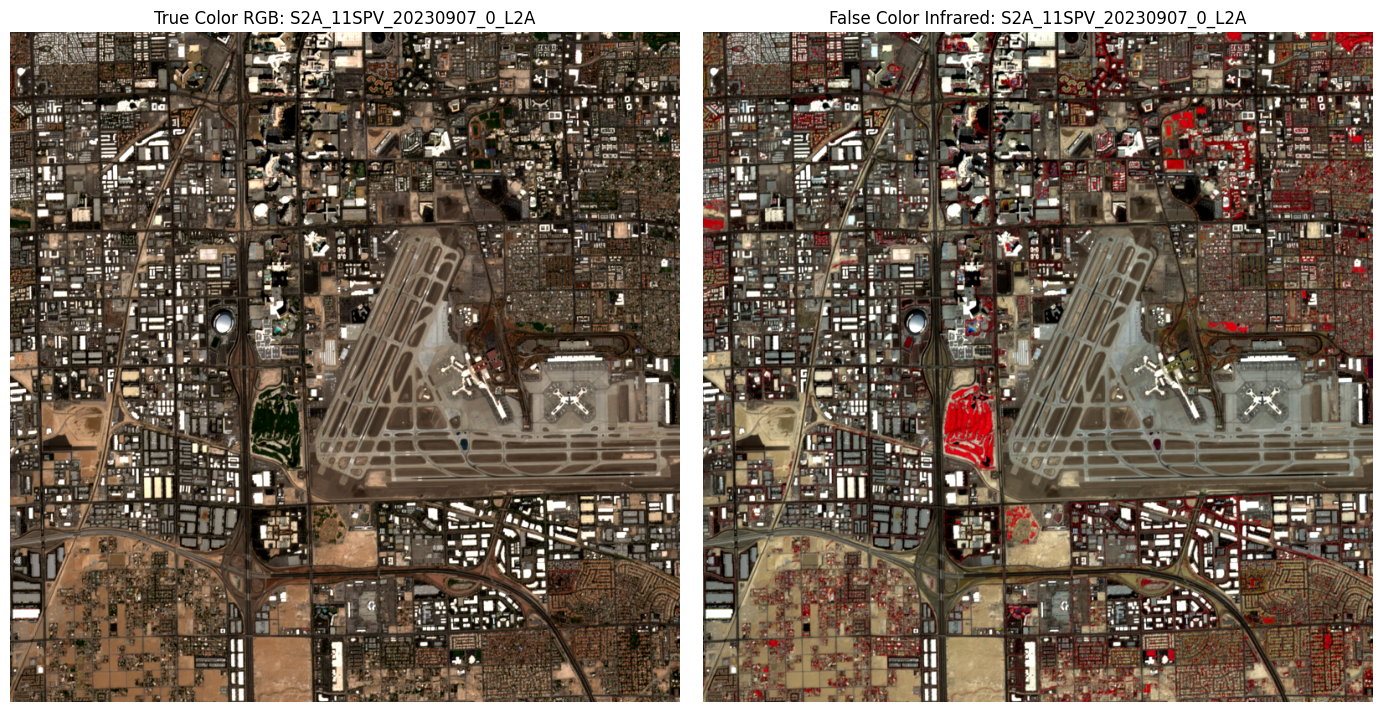

In [7]:
# Stack bands derived exclusively from the STAC Item
rgb = np.dstack([
    streamed_bands["Red"], streamed_bands["Green"], streamed_bands["Blue"]
])
cir = np.dstack([streamed_bands["NIR"], streamed_bands["Red"], streamed_bands["Green"]])

# Apply 2nd-to-98th percentile stretch for optical clarity
rgb_stretched = (
    np.clip(
        (rgb - np.percentile(rgb, 2))
        / (np.percentile(rgb, 98) - np.percentile(rgb, 2)),
        0.0,
        1.0,
    )
    ** 0.85
)

cir_stretched = (
    np.clip(
        (cir - np.percentile(cir, 2))
        / (np.percentile(cir, 98) - np.percentile(cir, 2)),
        0.0,
        1.0,
    )
    ** 0.85
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(rgb_stretched)
axes[0].set_title(f"True Color RGB: {stac_item.id}", fontsize=12)
axes[0].axis("off")

axes[1].imshow(cir_stretched)
axes[1].set_title(f"False Color Infrared: {stac_item.id}", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()